<a href="https://colab.research.google.com/github/amiralgmaly-glitch/vad-voices-research/blob/main/VAD_VOiCES_Comparison_Abdulameer_Aljmmali.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/amiralgmaly-glitch/vad-voices-research/blob/main/VAD_VOiCES_Comparison_Abdulameer_Aljmmali.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Robust Voice Activity Detection for Distant and Noisy Speech
## A Comparative Study of Classical and Neural Methods on the VOiCES Corpus

**Student:** Abdulameer Farhan Aljmmali
**Student ID:** 404131110
**Course:** Speech and Audio Processing

Companion code for the research paper. It compares five VAD systems on distant, noisy speech from VOiCES:

1. Energy-based detector (adaptive threshold)
2. WebRTC VAD (GMM, aggressiveness modes 0-3)
3. Silero VAD (pre-trained neural model)
4. MFCC features + gradient boosting (trained on VOiCES)
5. Spectrogram CNN (trained on VOiCES)

Reference labels come from the clean LibriSpeech source, aligned to each distant recording by cross-correlation. All systems are scored with frame-level (30 ms) precision, recall and F1 on a speaker-independent test split, broken down by distractor, microphone distance and room.

**Run:** `Runtime -> Run all`. A GPU runtime is optional (`Runtime -> Change runtime type -> T4 GPU`) and only speeds up the CNN.

## 1. Setup

In [16]:
# Install without touching Colab's own torch/torchaudio
!pip -q install librosa soundfile webrtcvad-wheels
!pip -q install --no-deps silero-vad

In [17]:
import os, re, glob, time, tarfile, random, warnings
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import soundfile as sf
import librosa
import requests
import torch, torch.nn as nn
from scipy.signal import correlate, correlation_lags, medfilt
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import precision_score, recall_score, f1_score
from IPython.display import display
warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

SR = 16000                 # VOiCES 16 kHz release
FRAME = 480                # 30 ms frames, no overlap
MEDIAN = 5                 # 150 ms median smoothing, applied to every system
CLASSES = ["none", "babb", "musi", "tele"]
CLASS_NAMES = {"none": "None", "babb": "Babble", "musi": "Music", "tele": "Television"}
MICS = {"01": "Near (mc01)", "05": "Across room (mc05)"}   # mc03 is not in the devkit
ROOMS = ["rm1", "rm2"]
PER_CELL = 8               # recordings per room x distractor x mic cell (24 cells -> 192 recordings)
PER_CELL_SPEAKER = 1       # at most 1 recording per speaker in a cell
MAX_PER_SPEAKER = 3        # at most 3 recordings per speaker overall -> 60+ different speakers
print("Device:", DEVICE)

Device: cuda


## 2. Download a balanced VOiCES subset

The devkit is one 27.5 GB archive on the public AWS bucket `lab41openaudiocorpus`. We stream it and keep only:
- every clean source file (`source-16k`, small), and
- `PER_CELL` foreground recordings for each room x distractor x microphone cell, using the studio microphones mc01 (near) and mc05 (across the room). The third studio microphone on that line, mc03, is not in the devkit.

Streaming stops once every cell is full and every needed source is present.

In [3]:
VOICES_URL = "https://lab41openaudiocorpus.s3.amazonaws.com/VOiCES_devkit.tar.gz"
# Keep the data and partial results on Google Drive, so a disconnected session can resume
USE_DRIVE = True
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = "/content/drive/MyDrive/voices_vad"
else:
    ROOT = "/content/voices_vad"
CACHE = os.path.join(ROOT, "cache"); os.makedirs(CACHE, exist_ok=True)
MAX_MINUTES = 60

KEY_RE = re.compile(r"-sp(\d+)-ch(\d+)-se?g(\d+)")
def utt_key(name):
    m = KEY_RE.search(os.path.basename(name))
    return m.groups() if m else None
def field(name, pattern):
    m = re.search(pattern, os.path.basename(name))
    return m.group(1) if m else None
def parse_distant(name):
    b = os.path.basename(name)
    return {"room": field(b, r"VOiCES-(rm\d)-"), "distractor": field(b, r"VOiCES-rm\d-([a-z]+)-"),
            "mic": field(b, r"-mc(\d+)-"), "speaker": field(b, r"-sp(\d+)-"), "key": utt_key(b)}

os.makedirs(ROOT, exist_ok=True)
def scan():
    distant = [p for p in glob.glob(f"{ROOT}/**/distant-16k/speech/**/*.wav", recursive=True)]
    sources = {utt_key(p): p for p in glob.glob(f"{ROOT}/**/source-16k/**/*.wav", recursive=True)}
    return distant, sources

distant, sources = scan()
cell_count = Counter((d["room"], d["distractor"], d["mic"]) for d in map(parse_distant, distant))
cell_spk = Counter((d["room"], d["distractor"], d["mic"], d["speaker"]) for d in map(parse_distant, distant))
spk_total = Counter(d["speaker"] for d in map(parse_distant, distant))
needed = {parse_distant(p)["key"] for p in distant}
cells = [(r, c, m) for r in ROOMS for c in CLASSES for m in MICS]
def complete():
    return all(cell_count[x] >= PER_CELL for x in cells) and needed <= set(sources)

if complete():
    print("Subset already on disk.")
else:
    t0, last = time.time(), 0
    with requests.get(VOICES_URL, stream=True, timeout=60) as resp:
        resp.raise_for_status()
        with tarfile.open(fileobj=resp.raw, mode="r|gz") as tar:
            for member in tar:
                if not member.isfile() or not member.name.endswith(".wav"):
                    continue
                name = member.name
                if "/source-16k/" in name:
                    tar.extract(member, ROOT); sources[utt_key(name)] = os.path.join(ROOT, name)
                elif "/distant-16k/speech/" in name:
                    d = parse_distant(name)
                    cell = (d["room"], d["distractor"], d["mic"])
                    if cell not in cells:
                        continue
                    if (cell_count[cell] >= PER_CELL or cell_spk[cell + (d["speaker"],)] >= PER_CELL_SPEAKER
                            or spk_total[d["speaker"]] >= MAX_PER_SPEAKER):
                        continue
                    tar.extract(member, ROOT)
                    cell_count[cell] += 1; cell_spk[cell + (d["speaker"],)] += 1; spk_total[d["speaker"]] += 1; needed.add(d["key"])
                done = sum(min(cell_count[x], PER_CELL) for x in cells)
                if done - last >= 24:
                    last = done
                    print(f"{(time.time()-t0)/60:5.1f} min | recordings {done}/{PER_CELL*len(cells)} | sources {len(sources)}")
                if complete():
                    print("Subset complete."); break
                if time.time() - t0 > MAX_MINUTES * 60:
                    print("Time limit reached; continuing with what was downloaded."); break
    print(f"Finished in {(time.time()-t0)/60:.1f} min")

Mounted at /content/drive
Subset already on disk.


## 3. Recording table and speaker-independent split

In [4]:
distant, sources = scan()
rows = []
for p in distant:
    d = parse_distant(p)
    if d["mic"] in MICS and d["distractor"] in CLASSES and d["key"] in sources:
        rows.append({**d, "path": p, "source": sources[d["key"]]})
rec = pd.DataFrame(rows).drop(columns="key").sort_values("path").reset_index(drop=True)

speakers = sorted(rec["speaker"].unique())
rng = np.random.default_rng(SEED); rng.shuffle(speakers)
n_train = int(round(0.7 * len(speakers)))
train_spk = set(speakers[:n_train])
rec["split"] = np.where(rec["speaker"].isin(train_spk), "train", "test")
assert not (set(rec.loc[rec.split == "train", "speaker"]) & set(rec.loc[rec.split == "test", "speaker"]))

print("Recordings:", len(rec), "| speakers:", len(speakers), f"(train {n_train}, test {len(speakers) - n_train})")
display(pd.crosstab([rec["room"], rec["mic"]], rec["distractor"]).reindex(columns=CLASSES))
display(rec["split"].value_counts().to_frame("recordings"))

Recordings: 128 | speakers: 55 (train 38, test 17)


distractor  none  babb  musi  tele
room mic                          
rm1  01        8     8     8     8
     05        8     8     8     8
rm2  01        8     8     8     8
     05        8     8     8     8

,recordings
split,
train,88
test,40


## 4. Reference labels from the clean source

1. Run the energy detector on the clean LibriSpeech source.
2. Find the delay between source and distant recording by cross-correlation.
3. Shift the source labels onto the distant recording's 30 ms frames.

In [5]:
def load(path):
    x, sr = sf.read(path, dtype="float32")
    if x.ndim == 2: x = x.mean(axis=1)
    if sr != SR: x = librosa.resample(x, orig_sr=sr, target_sr=SR)
    return x

def frames_of(x):
    n = len(x) // FRAME
    return x[: n * FRAME].reshape(n, FRAME)

def log_energy(x):
    return 10 * np.log10(np.mean(frames_of(x) ** 2, axis=1) + 1e-10)

def energy_vad(x, alpha):
    e = log_energy(x)
    lo, hi = np.percentile(e, 10), np.percentile(e, 95)
    return (e > lo + alpha * (hi - lo)).astype(np.int8)

def smooth(v, k=MEDIAN):
    return medfilt(v.astype(float), k).astype(np.int8) if len(v) >= k else v.astype(np.int8)

REF_ALPHA = 0.3
def reference_labels(y, s, max_lag_s=2.0):
    src = smooth(energy_vad(s, REF_ALPHA))                       # frame labels on clean source
    src_samples = np.repeat(src, FRAME)
    c = correlate(y, s[: len(src_samples)], mode="full", method="fft")
    lags = correlation_lags(len(y), len(src_samples), mode="full")
    ok = (lags >= -int(0.5 * SR)) & (lags <= int(max_lag_s * SR))
    i = np.argmax(np.abs(c) * ok)
    d = int(lags[i])
    peak = float(np.abs(c[i]) / (np.linalg.norm(y) * np.linalg.norm(s[: len(src_samples)]) + 1e-9))
    mask = np.zeros(len(y), dtype=np.int8)
    a0, a1 = max(0, d), min(len(y), d + len(src_samples))
    if a1 > a0:
        mask[a0:a1] = src_samples[a0 - d : a1 - d]
    ref = (frames_of(mask.astype(float)).mean(axis=1) > 0.5).astype(np.int8)
    return ref, d, peak

audio, refs, info = {}, {}, []
t0 = time.time()
for i, r in rec.iterrows():
    y, s = load(r.path), load(r.source)
    ref, d, peak = reference_labels(y, s)
    audio[i], refs[i] = y, ref
    info.append({"delay_ms": 1000 * d / SR, "xcorr_peak": peak, "speech_frac": ref.mean()})
rec = pd.concat([rec, pd.DataFrame(info)], axis=1)
print(f"Labels built in {time.time()-t0:.0f} s")
display(rec[["delay_ms", "xcorr_peak", "speech_frac"]].describe().round(3))

Labels built in 90 s


,delay_ms,xcorr_peak,speech_frac
count,128.000,128.000,128.000
mean,13.382,0.416,0.771
std,9.835,0.116,0.080
min,-2.375,0.188,0.430
25%,8.312,0.333,0.745
50%,12.125,0.393,0.796
75%,15.656,0.484,0.825
max,61.062,0.752,0.856


In [ ]:
# Visual check of one alignment (far microphone, babble)
i = rec.index[(rec.mic == "05") & (rec.distractor == "babb")][0]
y = audio[i]; t = np.arange(len(y)) / SR; tf = (np.arange(len(refs[i])) + 0.5) * FRAME / SR
plt.figure(figsize=(13, 3))
plt.plot(t, y / (np.abs(y).max() + 1e-9), lw=0.4, color="gray", label="distant recording")
plt.step(tf, refs[i] * 1.05, where="mid", color="tab:blue", label="reference speech")
plt.title(f"Reference labels on a distant recording ({rec.loc[i,'room']}, mic {rec.loc[i,'mic']}, babble, delay {rec.loc[i,'delay_ms']:.0f} ms)")
plt.xlabel("Time (s)"); plt.legend(loc="upper right"); plt.tight_layout(); plt.show()

## 5. Evaluation helpers

In [ ]:
train_idx = list(rec.index[rec.split == "train"]); test_idx = list(rec.index[rec.split == "test"])
preds = {}   # system -> {recording index: smoothed frame decisions}

def prf(idx, sysname):
    yt = np.concatenate([refs[i] for i in idx]); yp = np.concatenate([preds[sysname][i] for i in idx])
    return (precision_score(yt, yp, zero_division=0), recall_score(yt, yp, zero_division=0), f1_score(yt, yp, zero_division=0))

def f1_on(idx, decisions):
    yt = np.concatenate([refs[i] for i in idx]); yp = np.concatenate([decisions[i] for i in idx])
    return f1_score(yt, yp, zero_division=0)

import pickle
def cached(name, compute):
    # load a system's predictions from Drive if saved earlier, else compute and save them
    path = os.path.join(CACHE, f"{name}_{len(rec)}.pkl")
    if os.path.exists(path):
        print(f"{name}: loaded saved predictions"); return pickle.load(open(path, "rb"))
    out = compute(); pickle.dump(out, open(path, "wb")); return out

def fit_len(v, n):
    v = np.asarray(v, dtype=np.int8)[:n]
    return np.pad(v, (0, n - len(v))) if len(v) < n else v

## 6. System 1 - Energy detector (threshold tuned on training speakers)

In [8]:
def run_energy():
    alphas = [0.2, 0.3, 0.4, 0.5, 0.6]
    scores = {a: f1_on(train_idx, {i: smooth(energy_vad(audio[i], a)) for i in train_idx}) for a in alphas}
    a = max(scores, key=scores.get)
    print("Train F1 by alpha:", {k: round(v, 3) for k, v in scores.items()}, "-> best alpha", a)
    return {"best": a, "pred": {i: fit_len(smooth(energy_vad(audio[i], a)), len(refs[i])) for i in rec.index}}
r = cached("energy", run_energy); best_alpha = r["best"]; preds["Energy"] = r["pred"]

energy: loaded saved predictions


## 7. System 2 - WebRTC VAD (mode chosen on training speakers)

In [9]:
import webrtcvad
def webrtc_frames(x, mode):
    v = webrtcvad.Vad(mode)
    pcm = (np.clip(x, -1, 1) * 32767).astype(np.int16)
    return np.array([v.is_speech(f.tobytes(), SR) for f in frames_of(pcm)], dtype=np.int8)

def run_webrtc():
    scores = {m: f1_on(train_idx, {i: smooth(webrtc_frames(audio[i], m)) for i in train_idx}) for m in range(4)}
    m = max(scores, key=scores.get)
    print("Train F1 by mode:", {k: round(v, 3) for k, v in scores.items()}, "-> best mode", m)
    return {"best": m, "pred": {i: fit_len(smooth(webrtc_frames(audio[i], m)), len(refs[i])) for i in rec.index}}
r = cached("webrtc", run_webrtc); best_mode = r["best"]; preds["WebRTC VAD"] = r["pred"]

webrtc: loaded saved predictions


## 8. System 3 - Silero VAD (pre-trained, threshold 0.5)

In [10]:
from silero_vad import load_silero_vad
silero = load_silero_vad()
WIN = 512   # 32 ms at 16 kHz

def silero_frames(x, thr=0.5):
    silero.reset_states()
    n = len(x) // WIN
    with torch.no_grad():
        probs = np.array([silero(torch.from_numpy(x[k*WIN:(k+1)*WIN].copy()), SR).item() for k in range(n)])
    centres_w = (np.arange(n) + 0.5) * WIN
    centres_f = (np.arange(len(x) // FRAME) + 0.5) * FRAME
    return (np.interp(centres_f, centres_w, probs) > thr).astype(np.int8)

t0 = time.time()
preds["Silero VAD"] = cached("silero", lambda: {i: fit_len(smooth(silero_frames(audio[i])), len(refs[i])) for i in rec.index})
print(f"Silero done in {time.time()-t0:.0f} s")

silero: loaded saved predictions
Silero done in 0 s


## 9. System 4 - MFCC features + gradient boosting (trained on VOiCES)

In [11]:
def frame_spec_input(x):
    # pad so that n_fft=512 / hop=480 / center=False gives exactly len(x)//FRAME frames
    n = len(x) // FRAME
    return np.pad(x[: n * FRAME], (0, 32)), n

def mfcc_features(x):
    xp, n = frame_spec_input(x)
    m = librosa.feature.mfcc(y=xp, sr=SR, n_mfcc=13, n_fft=512, hop_length=FRAME, win_length=FRAME, center=False)[:, :n]
    d1 = librosa.feature.delta(m, width=5, mode="nearest"); d2 = librosa.feature.delta(m, order=2, width=5, mode="nearest")
    e = log_energy(x)[None, :n]
    f = np.vstack([m, d1, d2, e]).T                      # (n, 40)
    pad = np.pad(f, ((2, 2), (0, 0)), mode="edge")        # +-2 frames of context
    return np.hstack([pad[k : k + n] for k in range(5)]).astype(np.float32)   # (n, 200)

def run_mfcc():
    t0 = time.time()
    feats = {i: mfcc_features(audio[i]) for i in rec.index}
    Xtr = np.vstack([feats[i] for i in train_idx]); ytr = np.concatenate([refs[i] for i in train_idx])
    print("MFCC training frames:", Xtr.shape, "| speech share:", round(ytr.mean(), 3), f"| features in {time.time()-t0:.0f} s")
    gb = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.1, random_state=SEED).fit(Xtr, ytr)
    print(f"trained in {time.time()-t0:.0f} s")
    return {i: fit_len(smooth((gb.predict_proba(feats[i])[:, 1] > 0.5).astype(np.int8)), len(refs[i])) for i in rec.index}
preds["MFCC + boosting"] = cached("mfcc", run_mfcc)

mfcc: loaded saved predictions


## 10. System 5 - Spectrogram CNN (trained on VOiCES)

In [12]:
CTX = 15   # frames per patch (450 ms), centred on the target frame
def logmel(x):
    xp, n = frame_spec_input(x)
    S = librosa.feature.melspectrogram(y=xp, sr=SR, n_fft=512, hop_length=FRAME, win_length=FRAME, center=False, n_mels=40)[:, :n]
    return np.log(S + 1e-6).astype(np.float32)           # (40, n)

class VADCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1), nn.BatchNorm2d(16), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Flatten(), nn.Linear(32 * 10 * 3, 64), nn.ReLU(), nn.Dropout(0.3), nn.Linear(64, 1))
    def forward(self, x): return self.net(x).squeeze(1)


def run_cnn():
    global mu, sd, mels, cnn
    mels = {i: logmel(audio[i]) for i in rec.index}
    mu = np.mean(np.hstack([mels[i] for i in train_idx]), axis=1, keepdims=True)
    sd = np.std(np.hstack([mels[i] for i in train_idx]), axis=1, keepdims=True) + 1e-6

    def patches(i):
        M = (mels[i] - mu) / sd
        P = np.pad(M, ((0, 0), (CTX // 2, CTX // 2)), mode="edge")
        n = M.shape[1]
        return np.stack([P[:, k : k + CTX] for k in range(n)])[:, None]   # (n, 1, 40, 15)

    Ptr = torch.from_numpy(np.concatenate([patches(i) for i in train_idx]))
    Ytr = torch.from_numpy(np.concatenate([refs[i] for i in train_idx]).astype(np.float32))
    print("CNN training patches:", tuple(Ptr.shape))

    cnn = VADCNN().to(DEVICE)
    opt = torch.optim.Adam(cnn.parameters(), lr=1e-3); lossf = nn.BCEWithLogitsLoss()
    for epoch in range(5):
        cnn.train(); perm = torch.randperm(len(Ptr)); total = 0.0
        for b in range(0, len(Ptr), 256):
            idx = perm[b : b + 256]
            xb, yb = Ptr[idx].to(DEVICE), Ytr[idx].to(DEVICE)
            opt.zero_grad(); loss = lossf(cnn(xb), yb); loss.backward(); opt.step()
            total += loss.item() * len(idx)
        print(f"epoch {epoch+1}: loss {total/len(Ptr):.4f}")

    cnn.eval()
    def cnn_frames(i):
        with torch.no_grad():
            P = torch.from_numpy(patches(i))
            p = torch.cat([torch.sigmoid(cnn(P[b:b+1024].to(DEVICE))).cpu() for b in range(0, len(P), 1024)]).numpy()
        return (p > 0.5).astype(np.int8)
    return {i: fit_len(smooth(cnn_frames(i)), len(refs[i])) for i in rec.index}

preds["Spectrogram CNN"] = cached("cnn", run_cnn)

cnn: loaded saved predictions


## 11. Results (test speakers only)

In [13]:
SYSTEMS = ["Energy", "WebRTC VAD", "Silero VAD", "MFCC + boosting", "Spectrogram CNN"]
test = rec.loc[test_idx]

# Table III - overall
t3 = pd.DataFrame([dict(zip(["System", "Precision", "Recall", "F1"], (s, *prf(test_idx, s)))) for s in SYSTEMS]).set_index("System")
t3 = t3.rename(index={"WebRTC VAD": f"WebRTC VAD (mode {best_mode})"})
print("Table III. Overall frame-level results on the test speakers"); display(t3.round(3))

def f1_table(col, order, names):
    out = {}
    for s in SYSTEMS:
        row = {}
        for v in order:
            idx = list(test.index[test[col] == v])
            row[names[v]] = prf(idx, s)[2] if idx else float("nan")   # empty group -> NaN
        out[s] = row
    return pd.DataFrame(out).T

t4 = f1_table("distractor", CLASSES, CLASS_NAMES)
t5 = f1_table("mic", list(MICS), MICS)
t6 = f1_table("room", ROOMS, {"rm1": "Room 1", "rm2": "Room 2"})
print("Table IV. F1 by distractor type"); display(t4.round(3))
print("Table V. F1 by microphone distance"); display(t5.round(3))
print("Table VI. F1 by room"); display(t6.round(3))

os.makedirs("results", exist_ok=True)
for name, t in [("table3_overall", t3), ("table4_distractor", t4), ("table5_distance", t5), ("table6_room", t6)]:
    t.round(4).to_csv(f"results/{name}.csv")
print("Saved CSV tables in ./results  | best energy alpha:", best_alpha, "| best WebRTC mode:", best_mode)

Table III. Overall frame-level results on the test speakers


,Precision,Recall,F1
System,,,
Energy,0.922,0.972,0.946
WebRTC VAD (mode 2),0.874,0.981,0.924
Silero VAD,0.911,0.978,0.944
MFCC + boosting,0.914,0.984,0.948
Spectrogram CNN,0.931,0.977,0.953


Table IV. F1 by distractor type


,None,Babble,Music,Television
Energy,0.932,0.950,0.964,0.947
WebRTC VAD,0.914,0.925,0.946,0.922
Silero VAD,0.925,0.939,0.955,0.956
MFCC + boosting,0.932,0.938,0.953,0.963
Spectrogram CNN,0.928,0.955,0.961,0.967


Table V. F1 by microphone distance


,Near (mc01),Across room (mc05)
Energy,0.950,0.943
WebRTC VAD,0.928,0.921
Silero VAD,0.947,0.941
MFCC + boosting,0.956,0.939
Spectrogram CNN,0.957,0.950


Table VI. F1 by room


,Room 1,Room 2
Energy,0.942,0.951
WebRTC VAD,0.923,0.926
Silero VAD,0.936,0.951
MFCC + boosting,0.934,0.960
Spectrogram CNN,0.941,0.965


Saved CSV tables in ./results  | best energy alpha: 0.2 | best WebRTC mode: 2


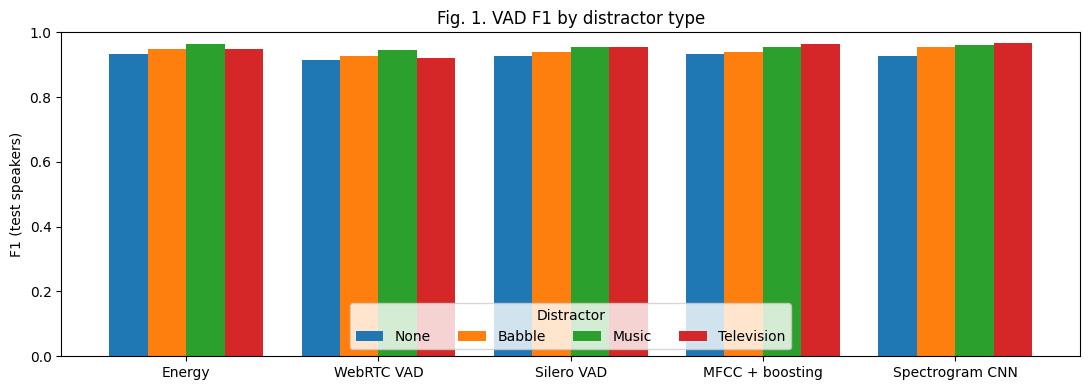

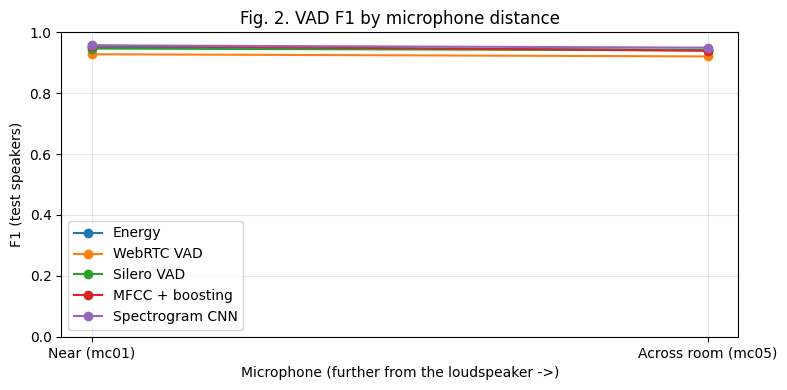

In [14]:
# Fig. 1 - F1 by distractor, one bar group per system
os.makedirs("results", exist_ok=True)
ax = t4.plot(kind="bar", figsize=(11, 4), width=0.8, ylim=(0, 1.0))
ax.set_ylabel("F1 (test speakers)"); ax.set_title("Fig. 1. VAD F1 by distractor type")
ax.tick_params(axis="x", rotation=0); ax.legend(title="Distractor", ncol=4, loc="lower center")
plt.tight_layout(); plt.savefig("results/fig1_distractor.png", dpi=200); plt.show()

# Fig. 2 - F1 against microphone distance, one line per system
fig, ax = plt.subplots(figsize=(8, 4))
for s in SYSTEMS:
    ax.plot(list(MICS.values()), t5.loc[s].values, marker="o", label=s)
ax.set_ylabel("F1 (test speakers)"); ax.set_xlabel("Microphone (further from the loudspeaker ->)")
ax.set_title("Fig. 2. VAD F1 by microphone distance"); ax.set_ylim(0, 1.0); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.savefig("results/fig2_distance.png", dpi=200); plt.show()

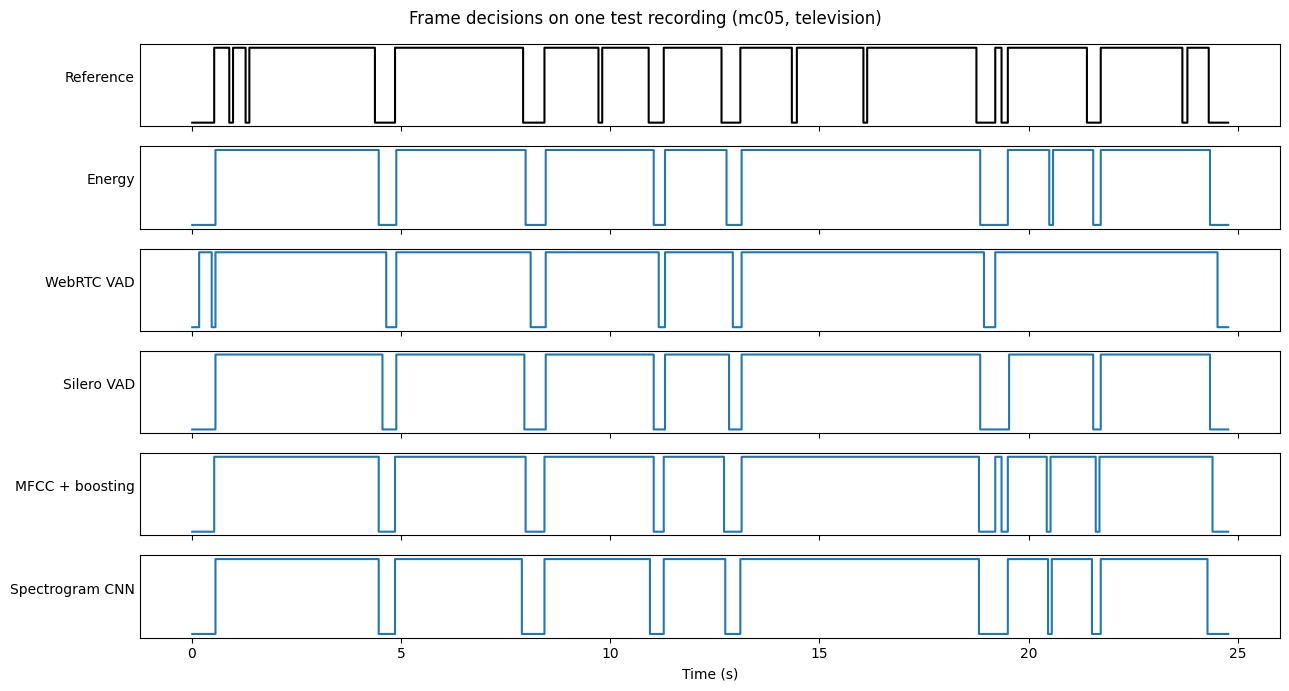

In [15]:
# Example decisions on one difficult test recording (across-room mic, television)
cand = test.index[(test.mic == "05") & (test.distractor == "tele")]
i = cand[0] if len(cand) else test.index[0]
tf = (np.arange(len(refs[i])) + 0.5) * FRAME / SR
fig, axes = plt.subplots(len(SYSTEMS) + 1, 1, figsize=(13, 7), sharex=True)
axes[0].step(tf, refs[i], where="mid", color="black"); axes[0].set_ylabel("Reference", rotation=0, ha="right")
for ax, s in zip(axes[1:], SYSTEMS):
    ax.step(tf, preds[s][i], where="mid"); ax.set_ylabel(s, rotation=0, ha="right")
for ax in axes: ax.set_yticks([])
axes[-1].set_xlabel("Time (s)"); fig.suptitle("Frame decisions on one test recording (mc05, television)")
plt.tight_layout(); plt.show()

## 12. Notes

- Copy Tables III-VI and Fig. 1-2 into Section V of the paper.
- The reference labels come from an energy detector on the clean source (Section 4), not manual annotation.
- Babble and television contain speech; frames where only the distractor speaks count as non-speech in the reference.
- Change `PER_CELL` in Section 1 to use more recordings (the download takes longer).